## Document classification - Simone Pellegrini

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

import nltk
from nltk.corpus import words
from nltk.tokenize import word_tokenize
from nltk.stem.wordnet import WordNetLemmatizer
from nltk.corpus import stopwords as sw
from sklearn.feature_extraction.text import TfidfVectorizer
import warnings
warnings.simplefilter("ignore")
import os
os.environ["PYTHONWARNINGS"] = "ignore" 
pd.set_option('display.max_colwidth', None)

np.random.seed(42)

label_names = {
    0: "International news",
    1: "Business",
    2: "Technology",
    3: "Entertainment",
    4: "Sports",
    5: "General news",
    6: "Health"
}


### Data Exploration

In [2]:
df = pd.read_csv("development.csv")
df

,Id,source,title,article,page_rank,timestamp,label
0,0,AllAfrica.com,OPEC Boosts Nigeria&#39;s Oil Revenue By .82m Bpd,"THE Organisation of Petroleum Exporting Countries (OPEC) is hiking its official output by one million barrels per day effective November with Nigeria getting 82,000 barrels per day or 8.2 per cent of the new quota.",5,2004-09-16 22:39:53,5
1,1,Xinhua,Yearender: Mideast peace roadmap reaches dead-end in 2004,"Looking back at the major events that took place in the Middle East in 2004, the death of veteran Palestinian leader Yasser Arafat is undoubtedly a world-shaker.",5,2004-12-17 19:01:14,0
2,2,Yahoo,Battleground Dispatches for Oct. 5 \\n (CQPolitics.com)\\n,"CQPolitics.com - Here are today's Battleground Dispatches Ã¢ÂÂ a roundup of what is going on right now in the year's hottest races, based on reports from local and national media.",5,2006-10-05 18:42:29,0
3,3,BBC,Air best to resuscitate newborns,"Air rather than oxygen should be used to resuscitate newborn babies and may even save lives, research suggests.",5,0000-00-00 00:00:00,0
4,4,Yahoo,High tech German train crash kills at least one \\n (Reuters)\\n,"<p><a href=""http://us.rd.yahoo.com/dailynews/rss/europe/*http://news.yahoo.com/s/nm/20060922/wl_nm/transport_germany_accident_dc""><img src=""http://d.yimg.com/us.yimg.com/p/rids/20060922/i/r83709231.jpg?x=47&y=130&sig=dF38yH9MhxP9zBLqrj3SMw--"" align=""left"" height=""130"" width=""47"" alt=""An aerial view shows the crash site of a Transrapid high-speed train in the northern German region of Emsland near the town of Lathen, September 22, 2006. REUTERS/Bodo Marks"" border=""0"" /></a>Reuters - A high tech German train \\ncarrying 29 people smashed into a maintenance vehicle on a \\ntrial run in northern Germany on Friday, killing at least one \\nand trapping 10 more in the wreckage, a local official said.</p><br clear=""all""/>",5,2006-09-22 17:28:57,0
...,...,...,...,...,...,...,...
79992,79992,Yahoo,Italy's embattled Prodi faces vote of confidence \\n (AFP)\\n,"<p><a href=""http://us.rd.yahoo.com/dailynews/rss/europe/*http://news.yahoo.com/s/afp/20080123/ts_afp/italypolitics""><img src=""http://d.yimg.com/us.yimg.com/p/afp/20080123/capt.sge.azb57.230108093216.photo00.photo.default-343x512.jpg?x=87&y=130&q=85&sig=UB3i4HieCQH_uLzJwTfqFQ--"" align=""left"" height=""130"" width=""87"" alt=""Italian Prime Minister Romano Prodi speaks before the lower house of the parliament yesterday. Prodi is preparing to face the first of two votes of confidence as his centre-left government teetered on the brink of collapse.(AFP/File/Andreas Solaro)"" border=""0"" /></a>AFP - Embattled Italian Prime Minister Romano Prodi prepared on Wednesday to face the first of two votes of confidence as his centre-left government teetered on the brink of collapse.</p><br clear=""all""/>",5,2008-01-23 11:39:35,0
79993,79993,All-Baseball.com,"Ding Dong, the Deal is Dead","As yesterday began, there was widespread anticipation that the three teams involved in the Johnson trade would send a signed agreement to Commissioner Bud Seligâs office so that he could approve the deal.",5,0000-00-00 00:00:00,4
79994,79994,Yahoo,Two bombs discovered in Sardinia after Berlusconi-Blair meet (AFP),"AFP - Police discovered two bombs near the Sardinian villa of Italian Prime Minister Silvio Berlusconi, just hours after he met his British counterpart Tony Blair on the island, the Ansa news agency said.",5,0000-00-00 00:00:00,0
79995,79995,Voice,Red Cross Report Alleges US Detainee Abuse at Guantanamo,"A report by the International Committee of the Red Cross, quoted Tuesday by the New York Times, accuses the US military of using interrogation tactics that amount to torture against prisoners",5,0000-00-00 00:00:00,3


In [3]:
df = df.drop(columns=["Id"])

In [4]:
df.describe()

,page_rank,label
count,79997.000000,79997.000000
mean,4.892958,2.262760
std,0.397603,1.970502
min,2.000000,0.000000
25%,5.000000,0.000000
50%,5.000000,2.000000
75%,5.000000,4.000000
max,5.000000,6.000000


In [5]:
df = df.dropna()

## Data exploration

In [6]:
df["label"].value_counts()

label
0    23542
5    13053
2    11160
1    10587
3     9977
4     8574
6     3102
Name: count, dtype: int64

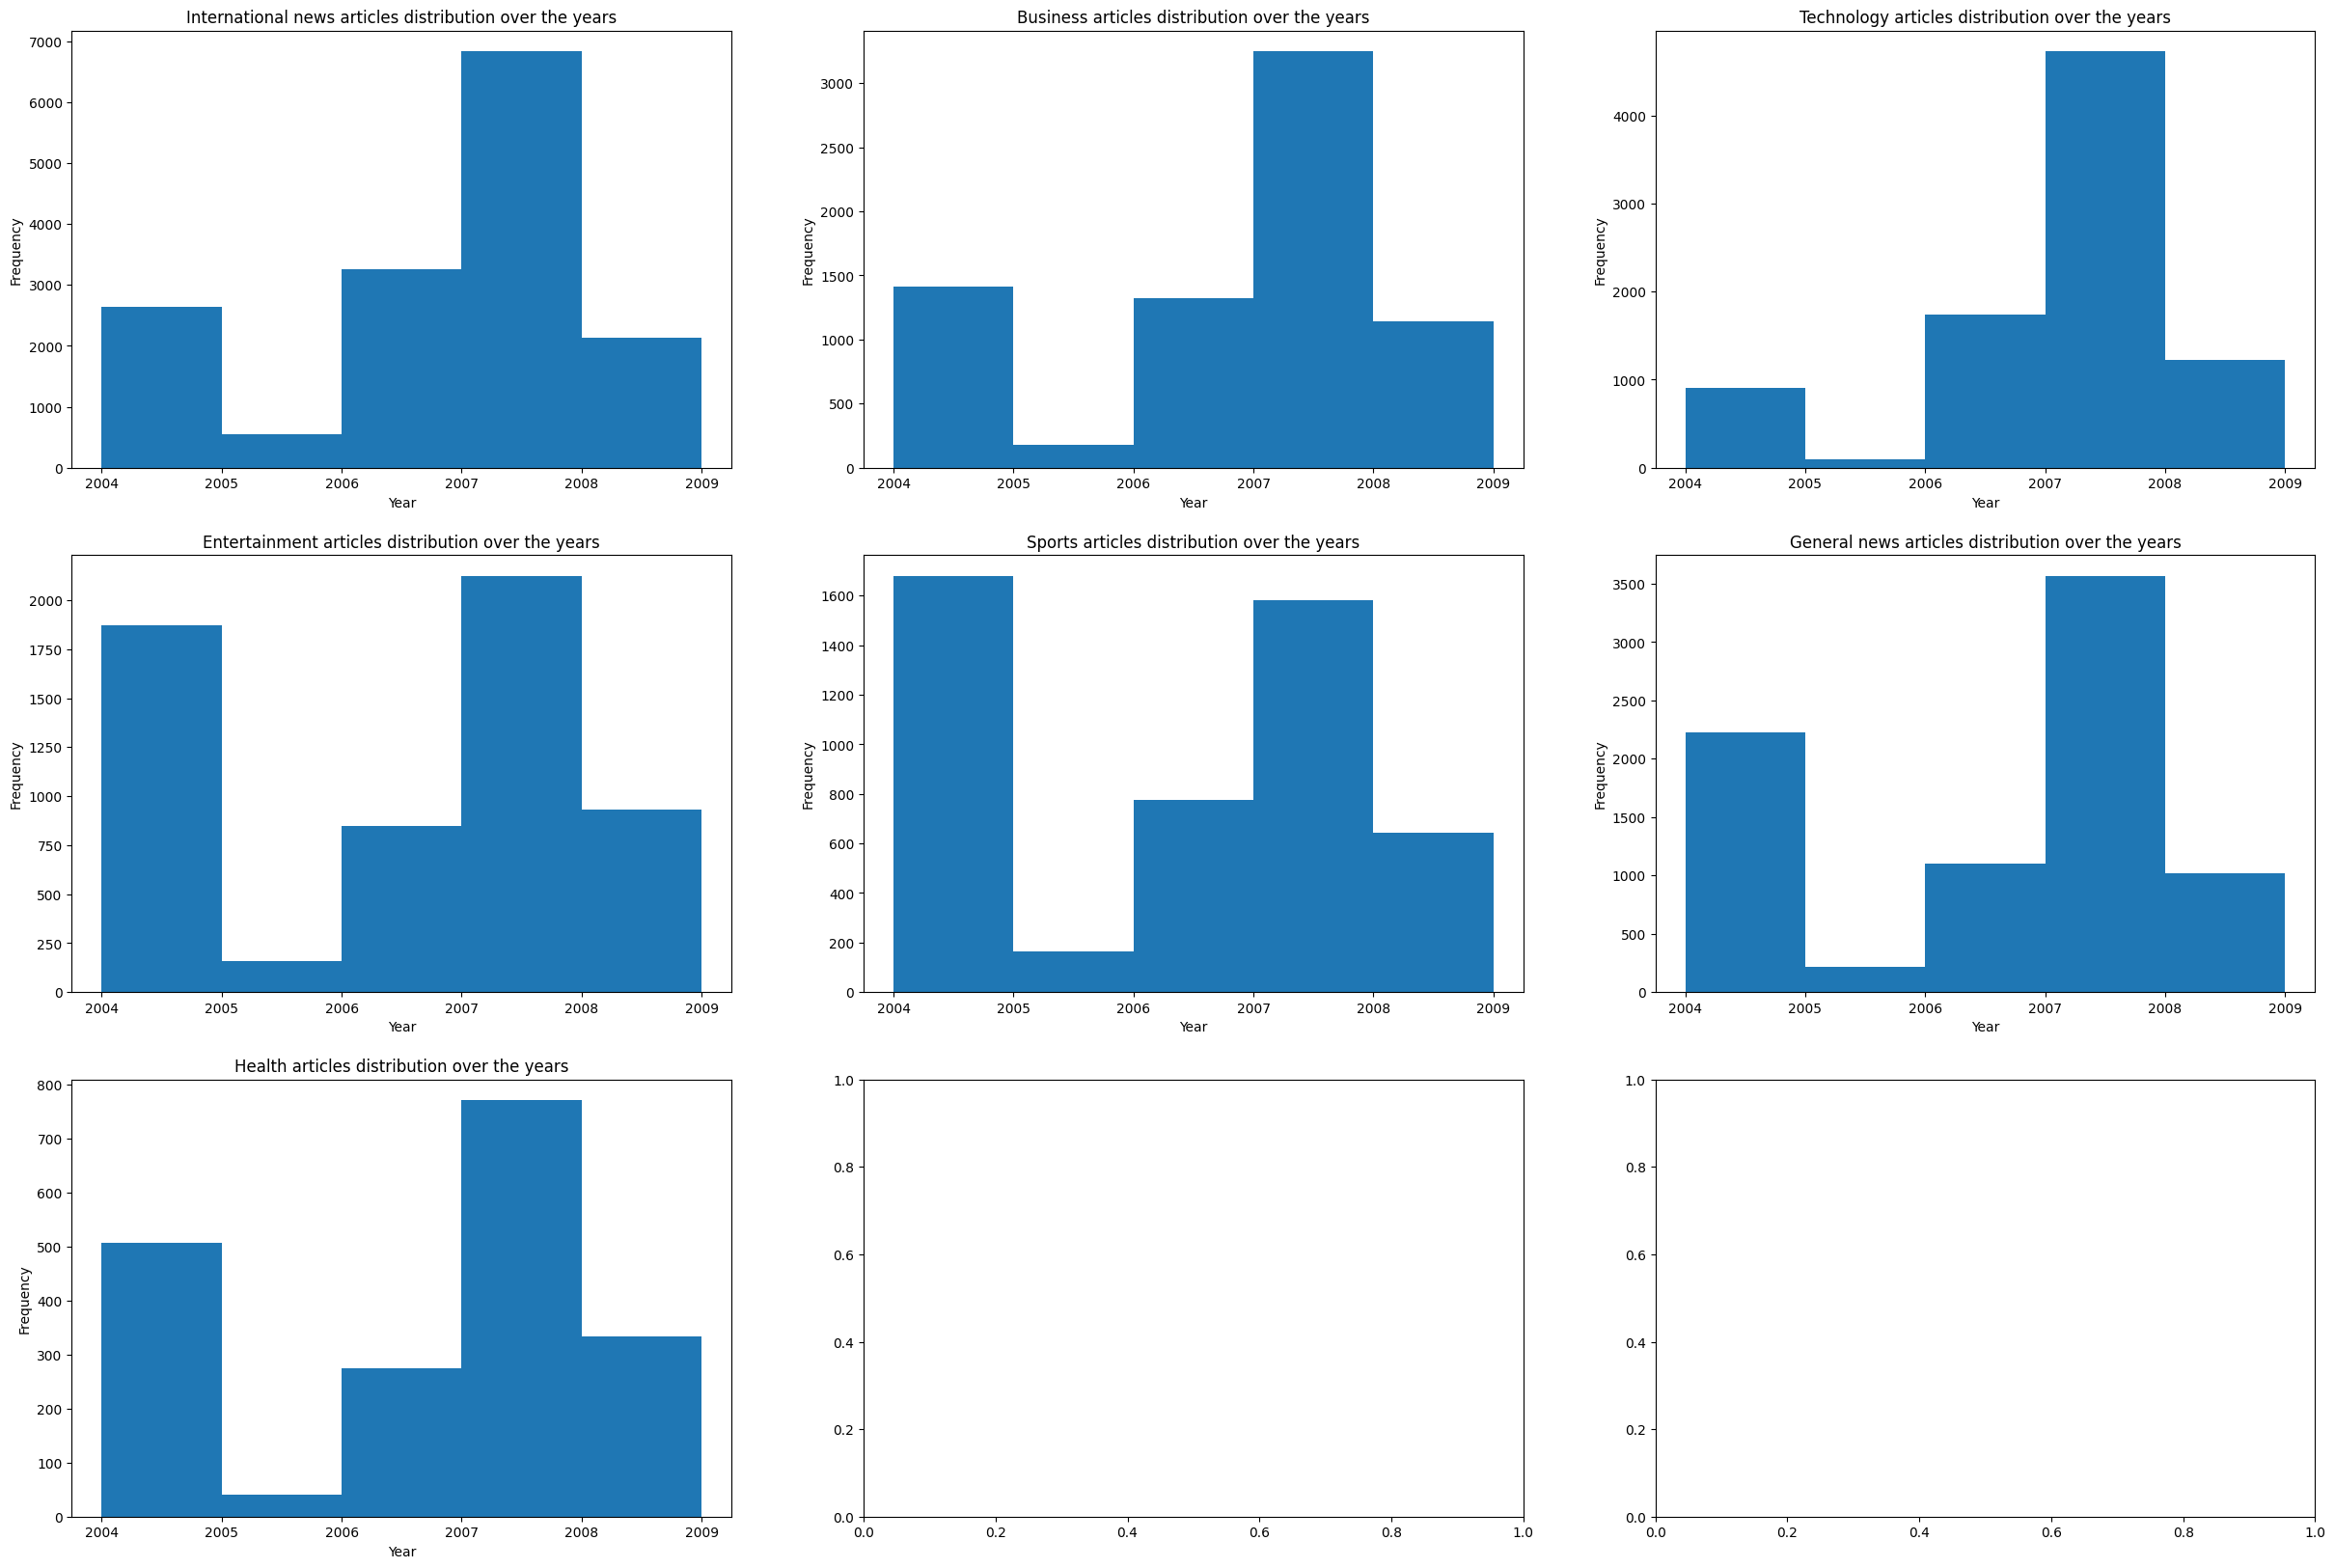

In [7]:
fig, ax = plt.subplots(3, 3, figsize=(30, 20))
ax = ax.flatten()

df_valid = df.copy()
df_valid["timestamp_dt"] = pd.to_datetime(df_valid["timestamp"], errors="coerce")
df_valid = df_valid.dropna(subset=["timestamp_dt"])

df_valid["year"] = df_valid["timestamp_dt"].dt.year
df_valid["month"] = df_valid["timestamp_dt"].dt.month

labels = sorted(df_valid["label"].unique())

for lbl in labels:
    subset = df_valid[df_valid["label"] == lbl]

    ax[lbl].hist(
        subset["year"],
        bins=range(int(subset["year"].min()), int(subset["year"].max()) + 2)
    )
    ax[lbl].set_xlabel("Year")
    ax[lbl].set_ylabel("Frequency")
    ax[lbl].set_title(label_names[lbl] + " articles distribution over the years")


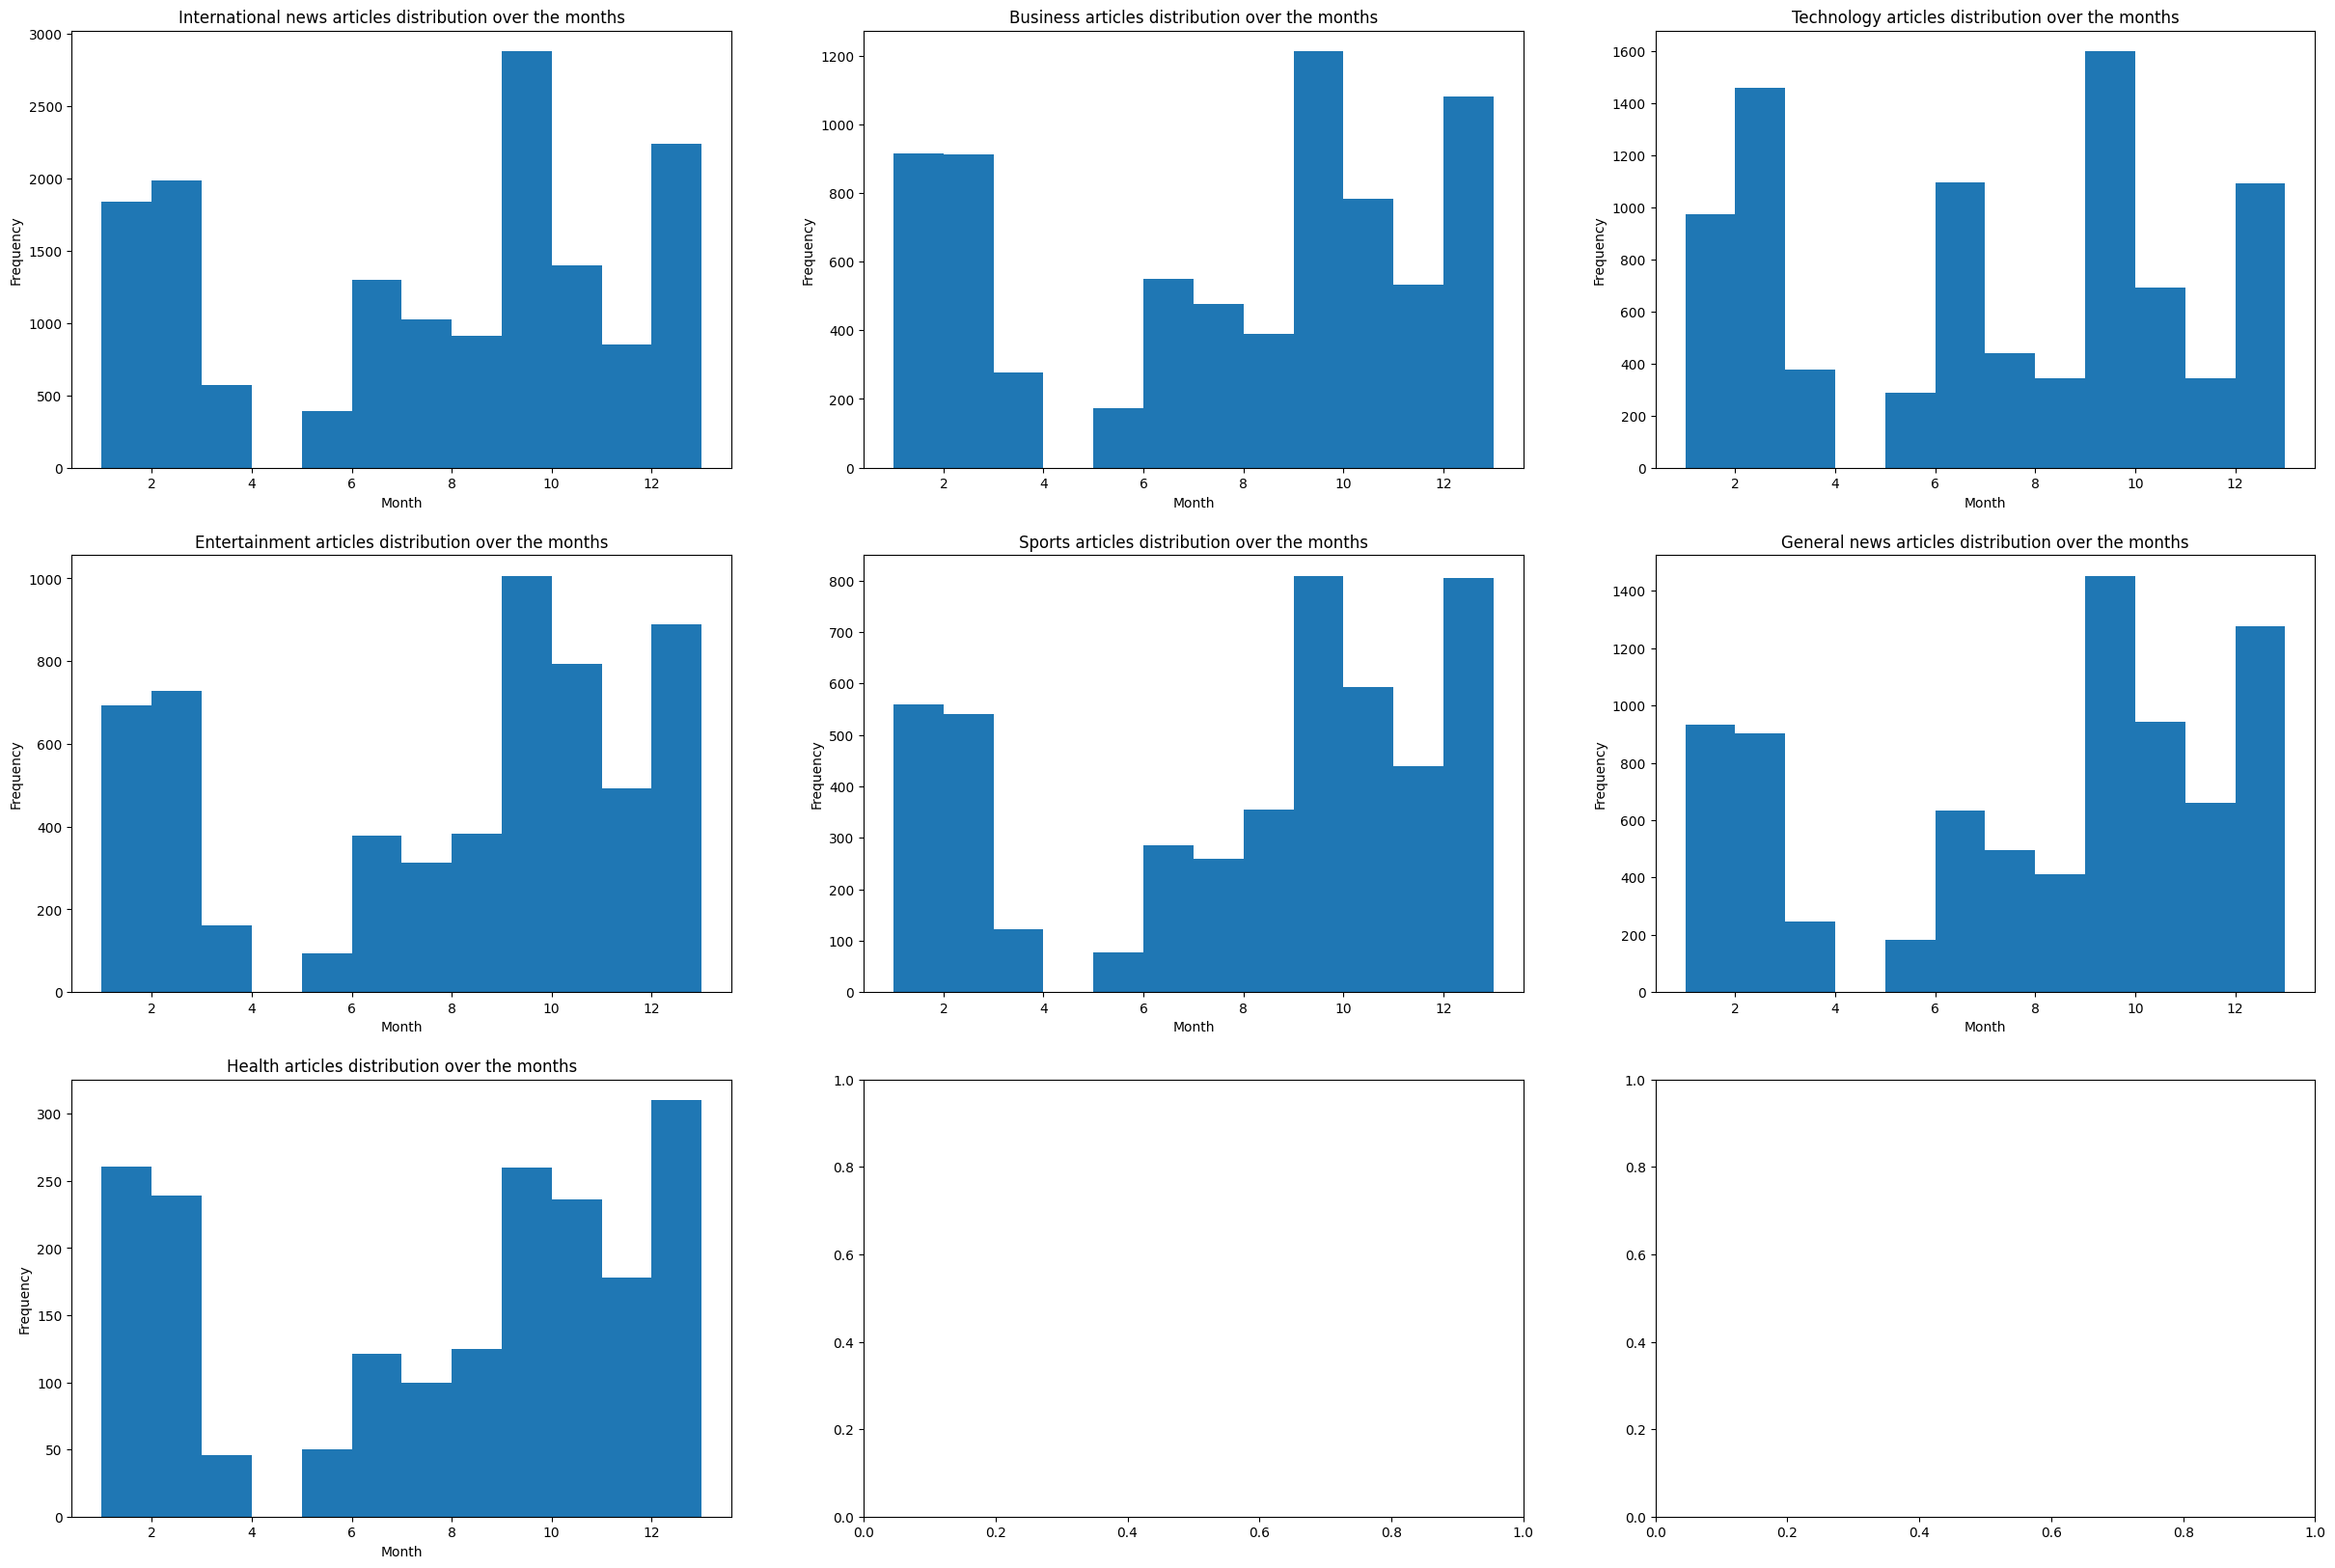

In [8]:
fig,ax = plt.subplots(3,3,figsize=(30,20))
ax = ax.flatten()

for lbl in labels:
    subset = df_valid[df_valid["label"] == lbl]

    ax[lbl].hist(
        subset["month"],
        bins=range(1, 14)
    )
    ax[lbl].set_xlabel("Month")
    ax[lbl].set_ylabel("Frequency")
    ax[lbl].set_title(label_names[lbl]+" articles distribution over the months")


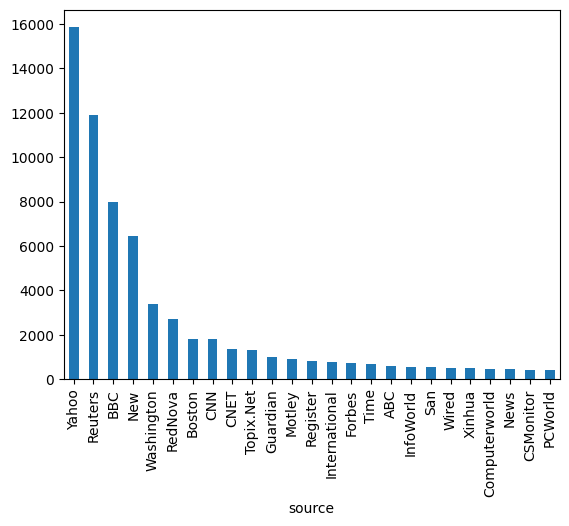

In [9]:
s = df["source"].value_counts()
perc = s.cumsum()/df.shape[0]
s = s[perc<=0.8]
s.plot(kind='bar')
plt.show()

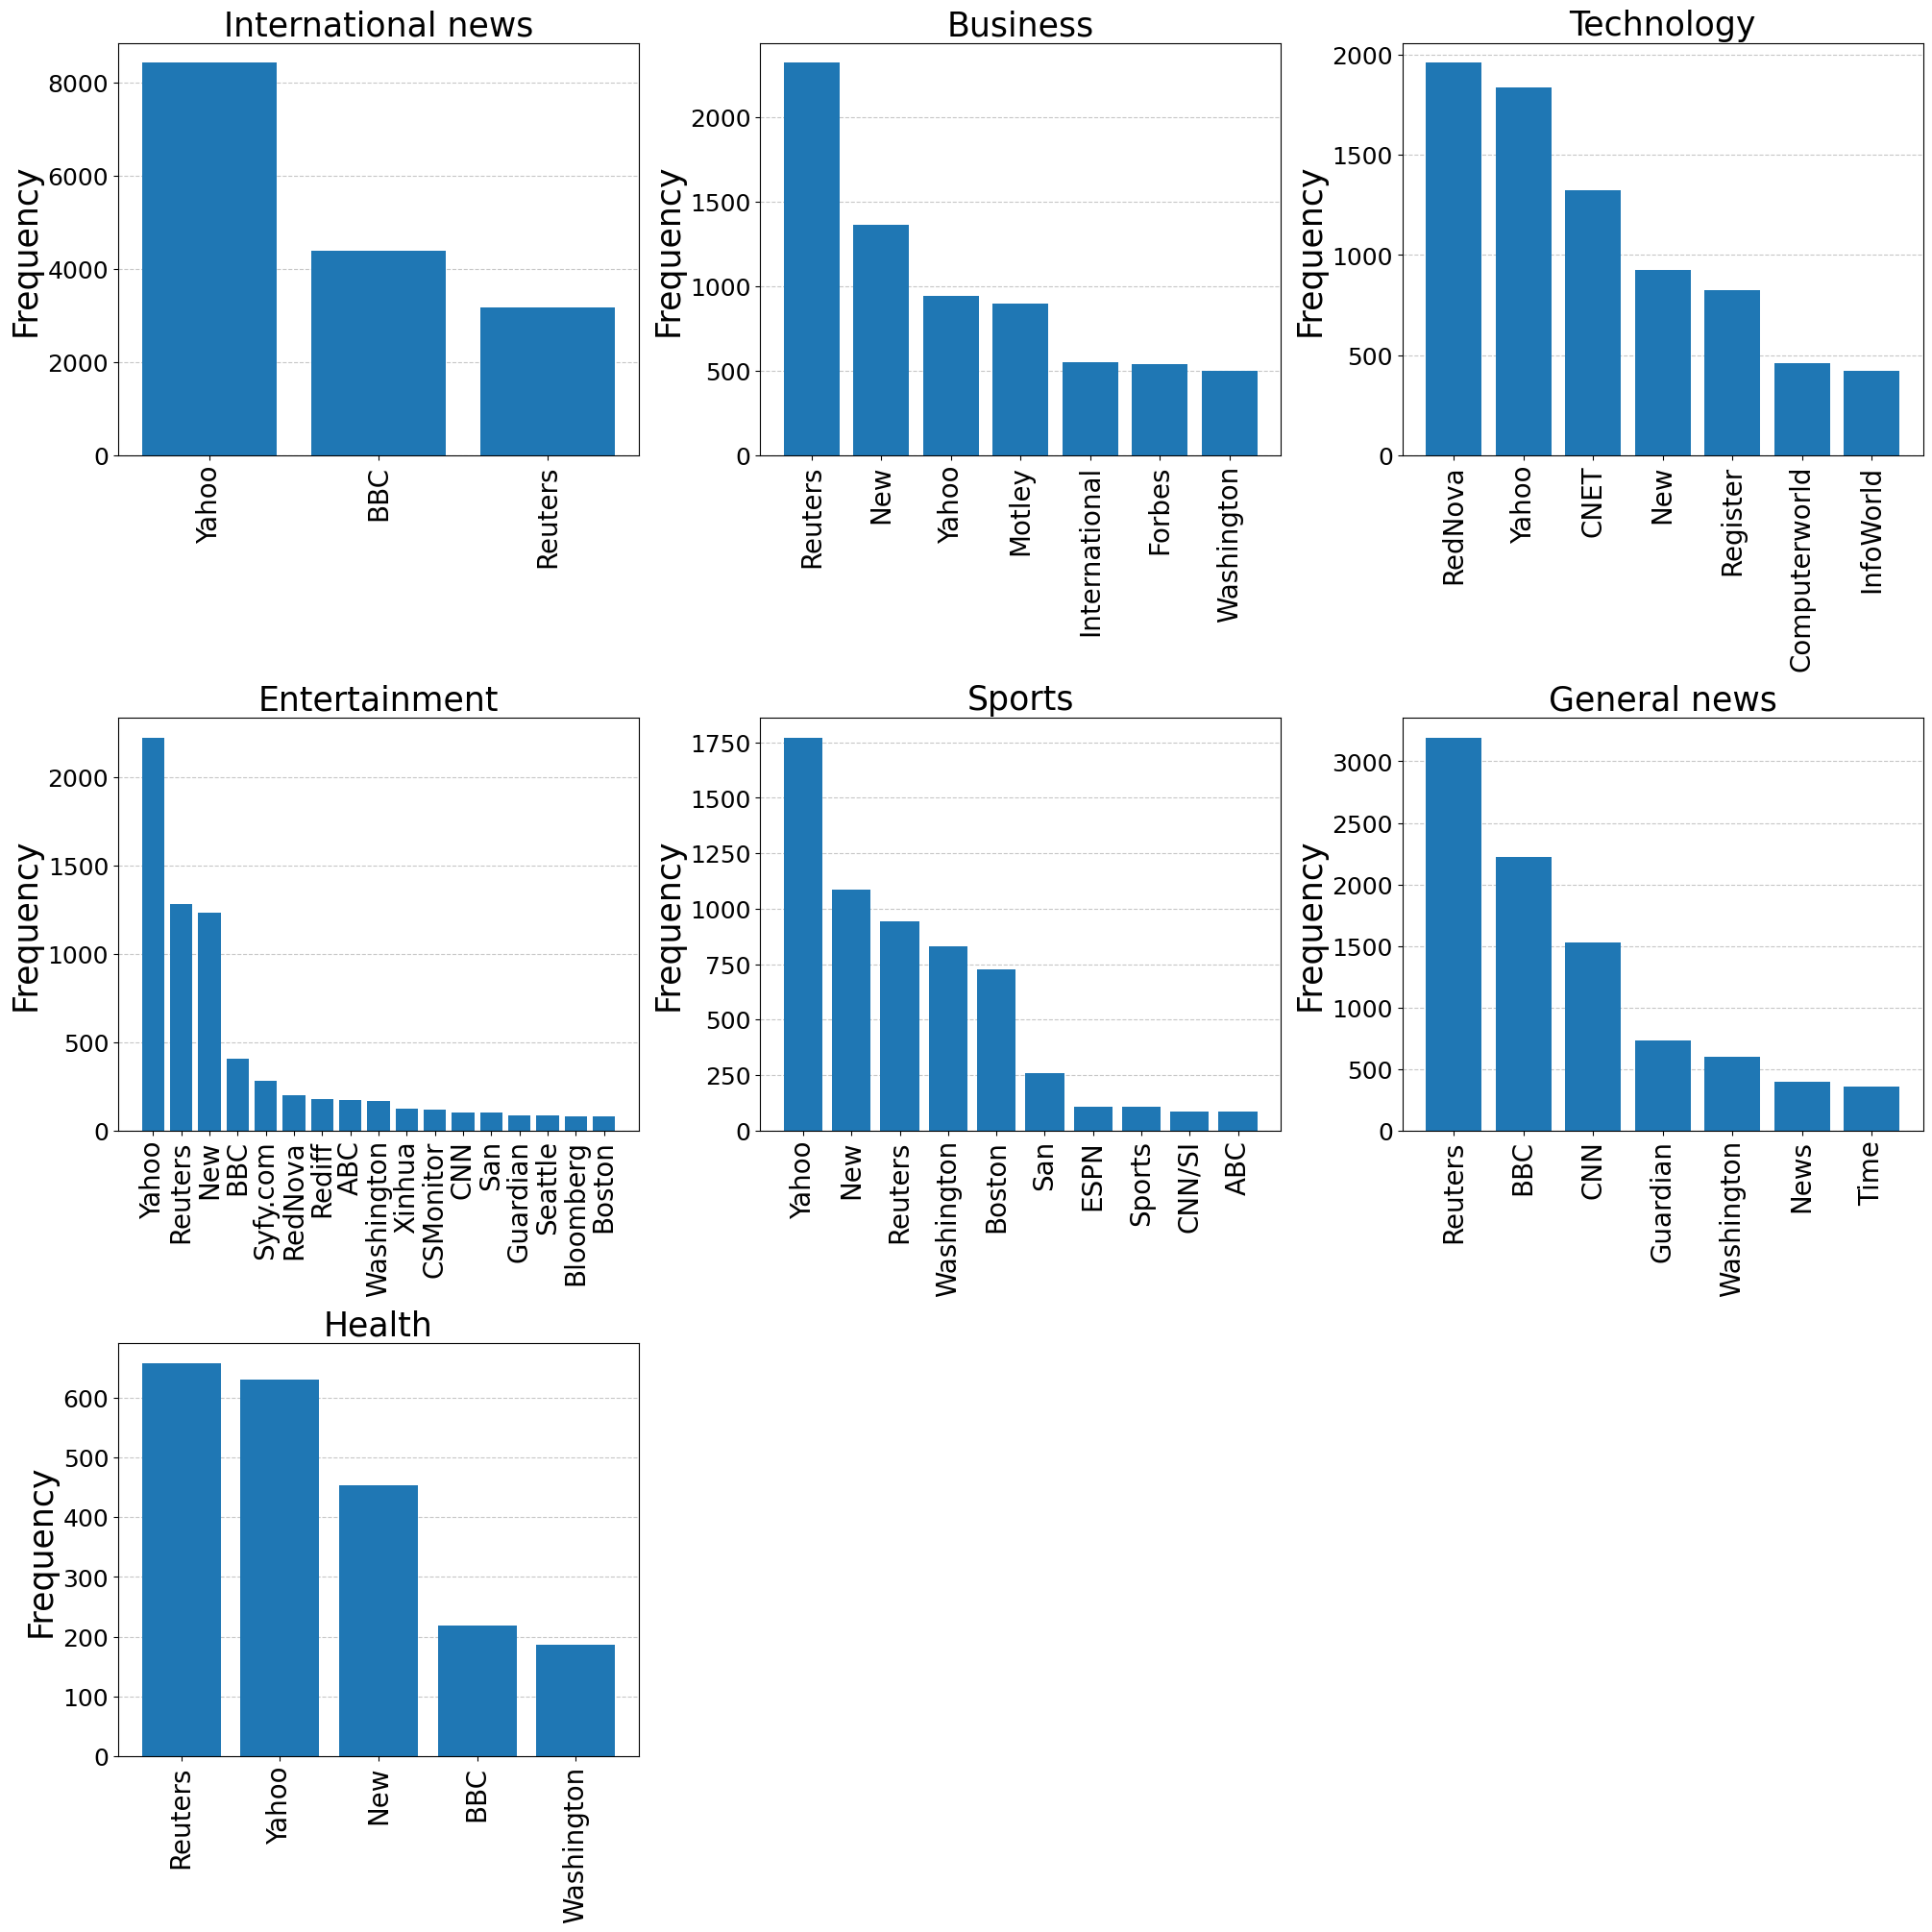

In [10]:
def extract_top_k(feature,df,freq,label):
    df = df[df['label']==label]
    s = df[feature].value_counts()
    perc = s.cumsum()/df.shape[0]
    s = s[perc<=freq]
    return s
    
fig, ax = plt.subplots(3,3, figsize=(20, 20), constrained_layout=True)
ax = ax.flatten()

for p,label in enumerate(range(7)):
    top_k = extract_top_k("source", df, 0.7, label)
    ax[p].set_title(label_names[label], fontsize=25)
    ax[p].bar(top_k.index, top_k.values)
    ax[p].tick_params(axis='x', labelrotation=90,labelsize=20)
    ax[p].tick_params(axis='y', labelsize=18)
    ax[p].grid(axis='y', linestyle='--', alpha=0.7)
    ax[p].set_axisbelow(True)
    ax[p].set_ylabel("Frequency",fontsize=25)

for i in range(7, len(ax)):
    fig.delaxes(ax[i])

plt.show()



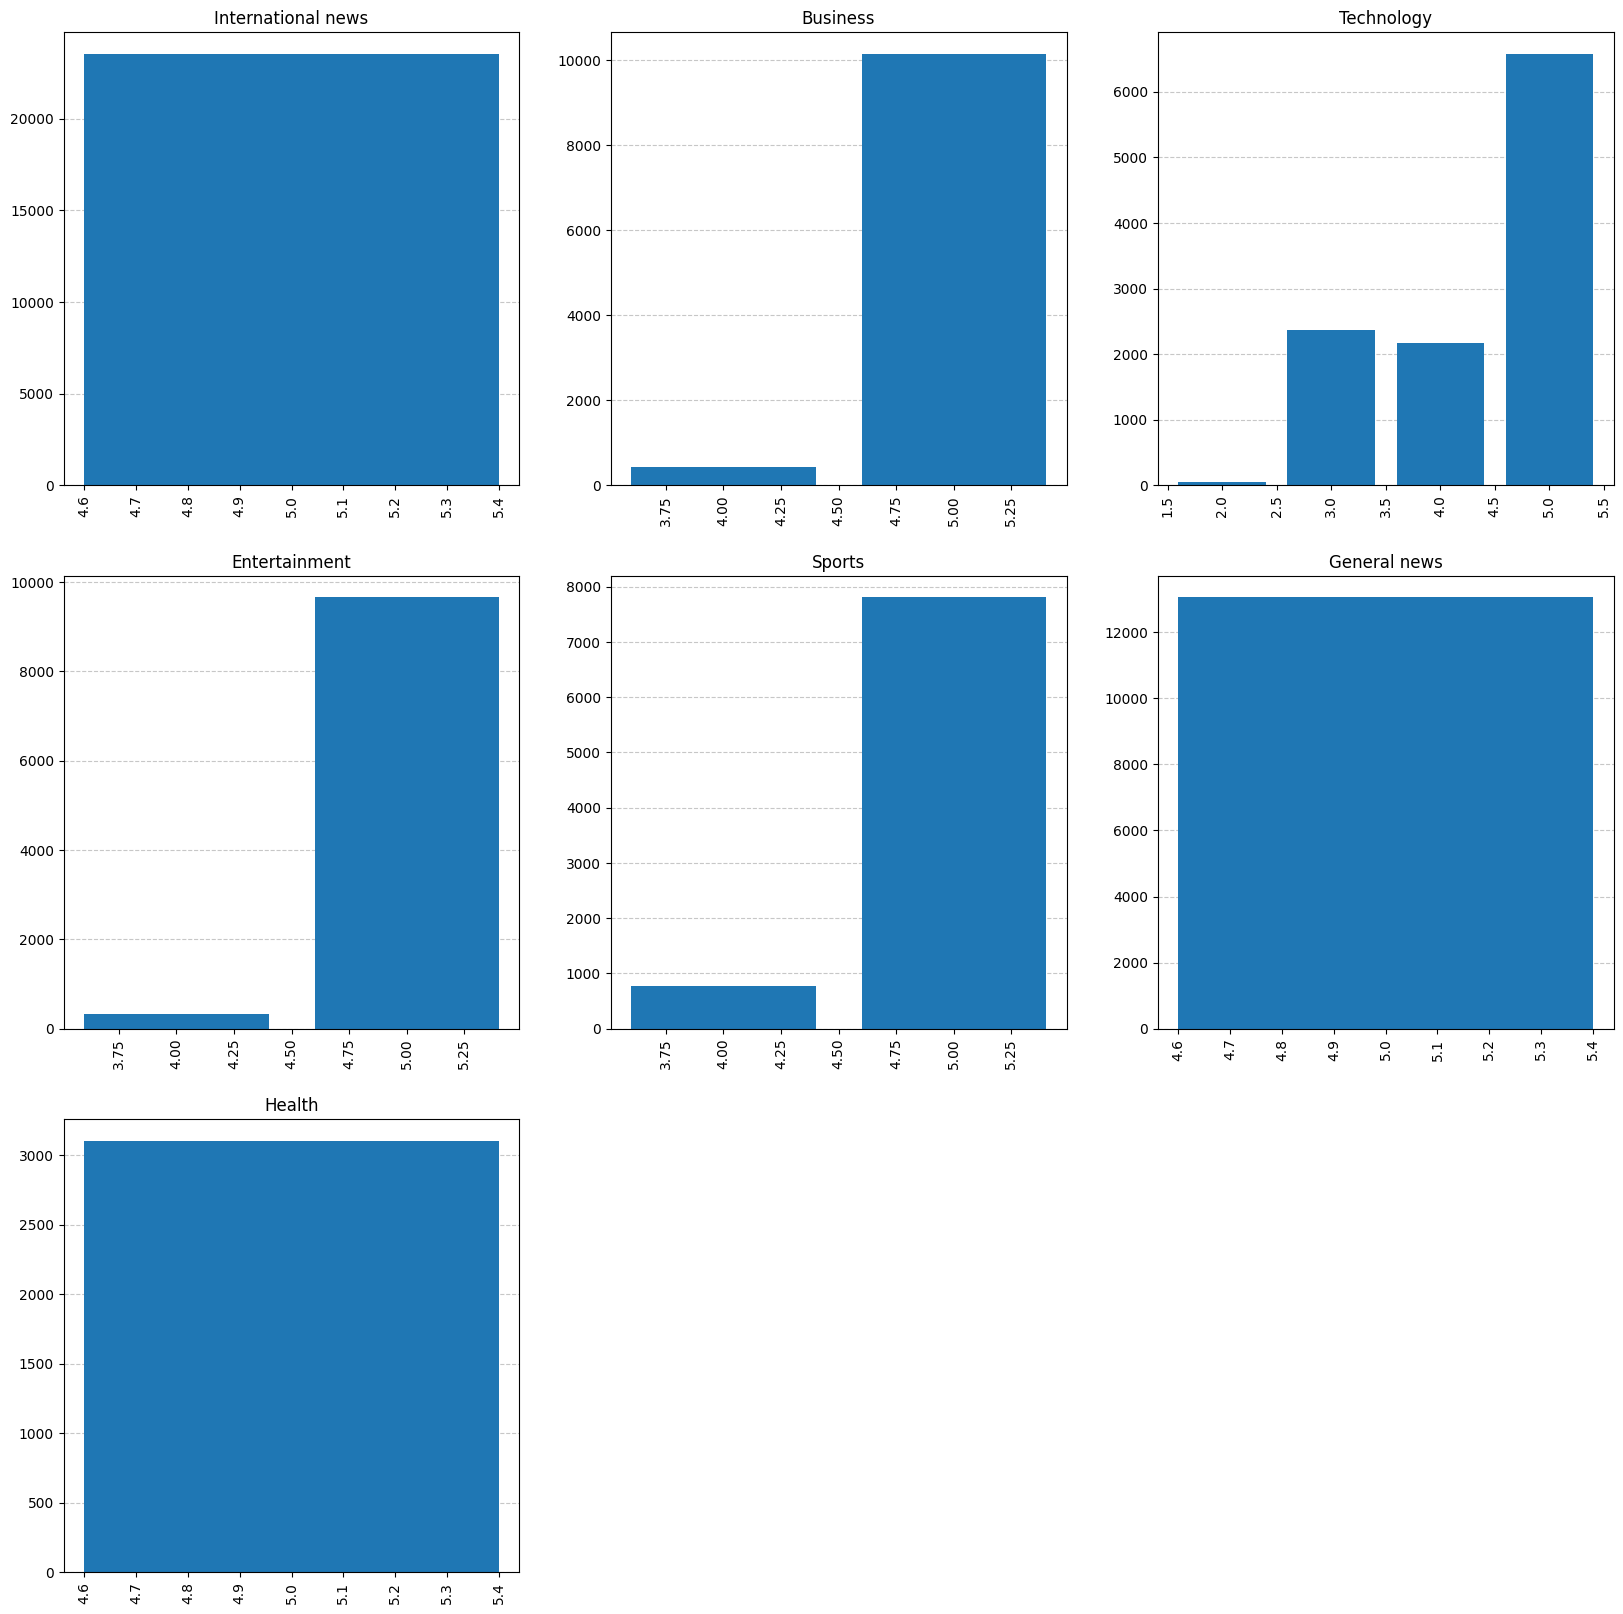

In [11]:
fig,ax = plt.subplots(3,3,figsize=(20,20))
ax = ax.flatten()
for label in range(7):
    s = df.loc[df["label"]==label,"page_rank"].value_counts()
    ax[label].set_title(label_names[label])
    ax[label].bar(s.index,s.values)
    ax[label].tick_params(axis='x', labelrotation=90)
    ax[label].grid(axis='y', linestyle='--', alpha=0.7)
    ax[label].set_axisbelow(True)

for i in range(7, len(ax)):
    fig.delaxes(ax[i])
    
plt.show()


In [12]:
import re

n_examples = 10
html_pattern = re.compile(r"<[^>]+>") 

count = 0
i = 0

while count < n_examples and 100 + i < len(df):
    article = df["article"][100 + i]

    if isinstance(article, str) and html_pattern.search(article):
        print("-----------------------")
        print("LABEL: ", label_names[df["label"][100 + i]])
        print("TITLE: ", df["title"][100 + i])
        print("ARTICLE: ", article)
        print("-----------------------\n")
        count += 1

    i += 1

-----------------------
LABEL:  International news
TITLE:  Iraq seeks oversight of rape-slaying case \
    (AP)\

ARTICLE:  <p><a href="http://us.rd.yahoo.com/dailynews/rss/world/*http://news.yahoo.com/s/ap/20060704/ap_on_re_mi_ea/iraq"><img src="http://us.news3.yimg.com/us.i2.yimg.com/p/ap/20060703/capt.8ec0c90a8a9041e884a7e75dba7940e7.iraq_us_investigation_nccb201.jpg?x=92&amp;y=130&amp;sig=v78JDnM85m.ISPLUiX6ENw--" align="left" height="130" width="92" alt="In this photo provided by the Mecklenburg County Sheriff's Office, Steven D. Green is shown in A booking mug shot at the Mecklenburg County jail in Charlotte, N.C., Monday, July 3, 2006. Green, a 21-year-old former Army private first class who was recently discharged because of a 'personality disorder,' appeared in a federal magistrate's courtroom in Charlotte Monday. The murder and rape charges against him grew out of a military investigation involving up to five soldiers in the March rape and killing of the woman in Mahmoudiya a

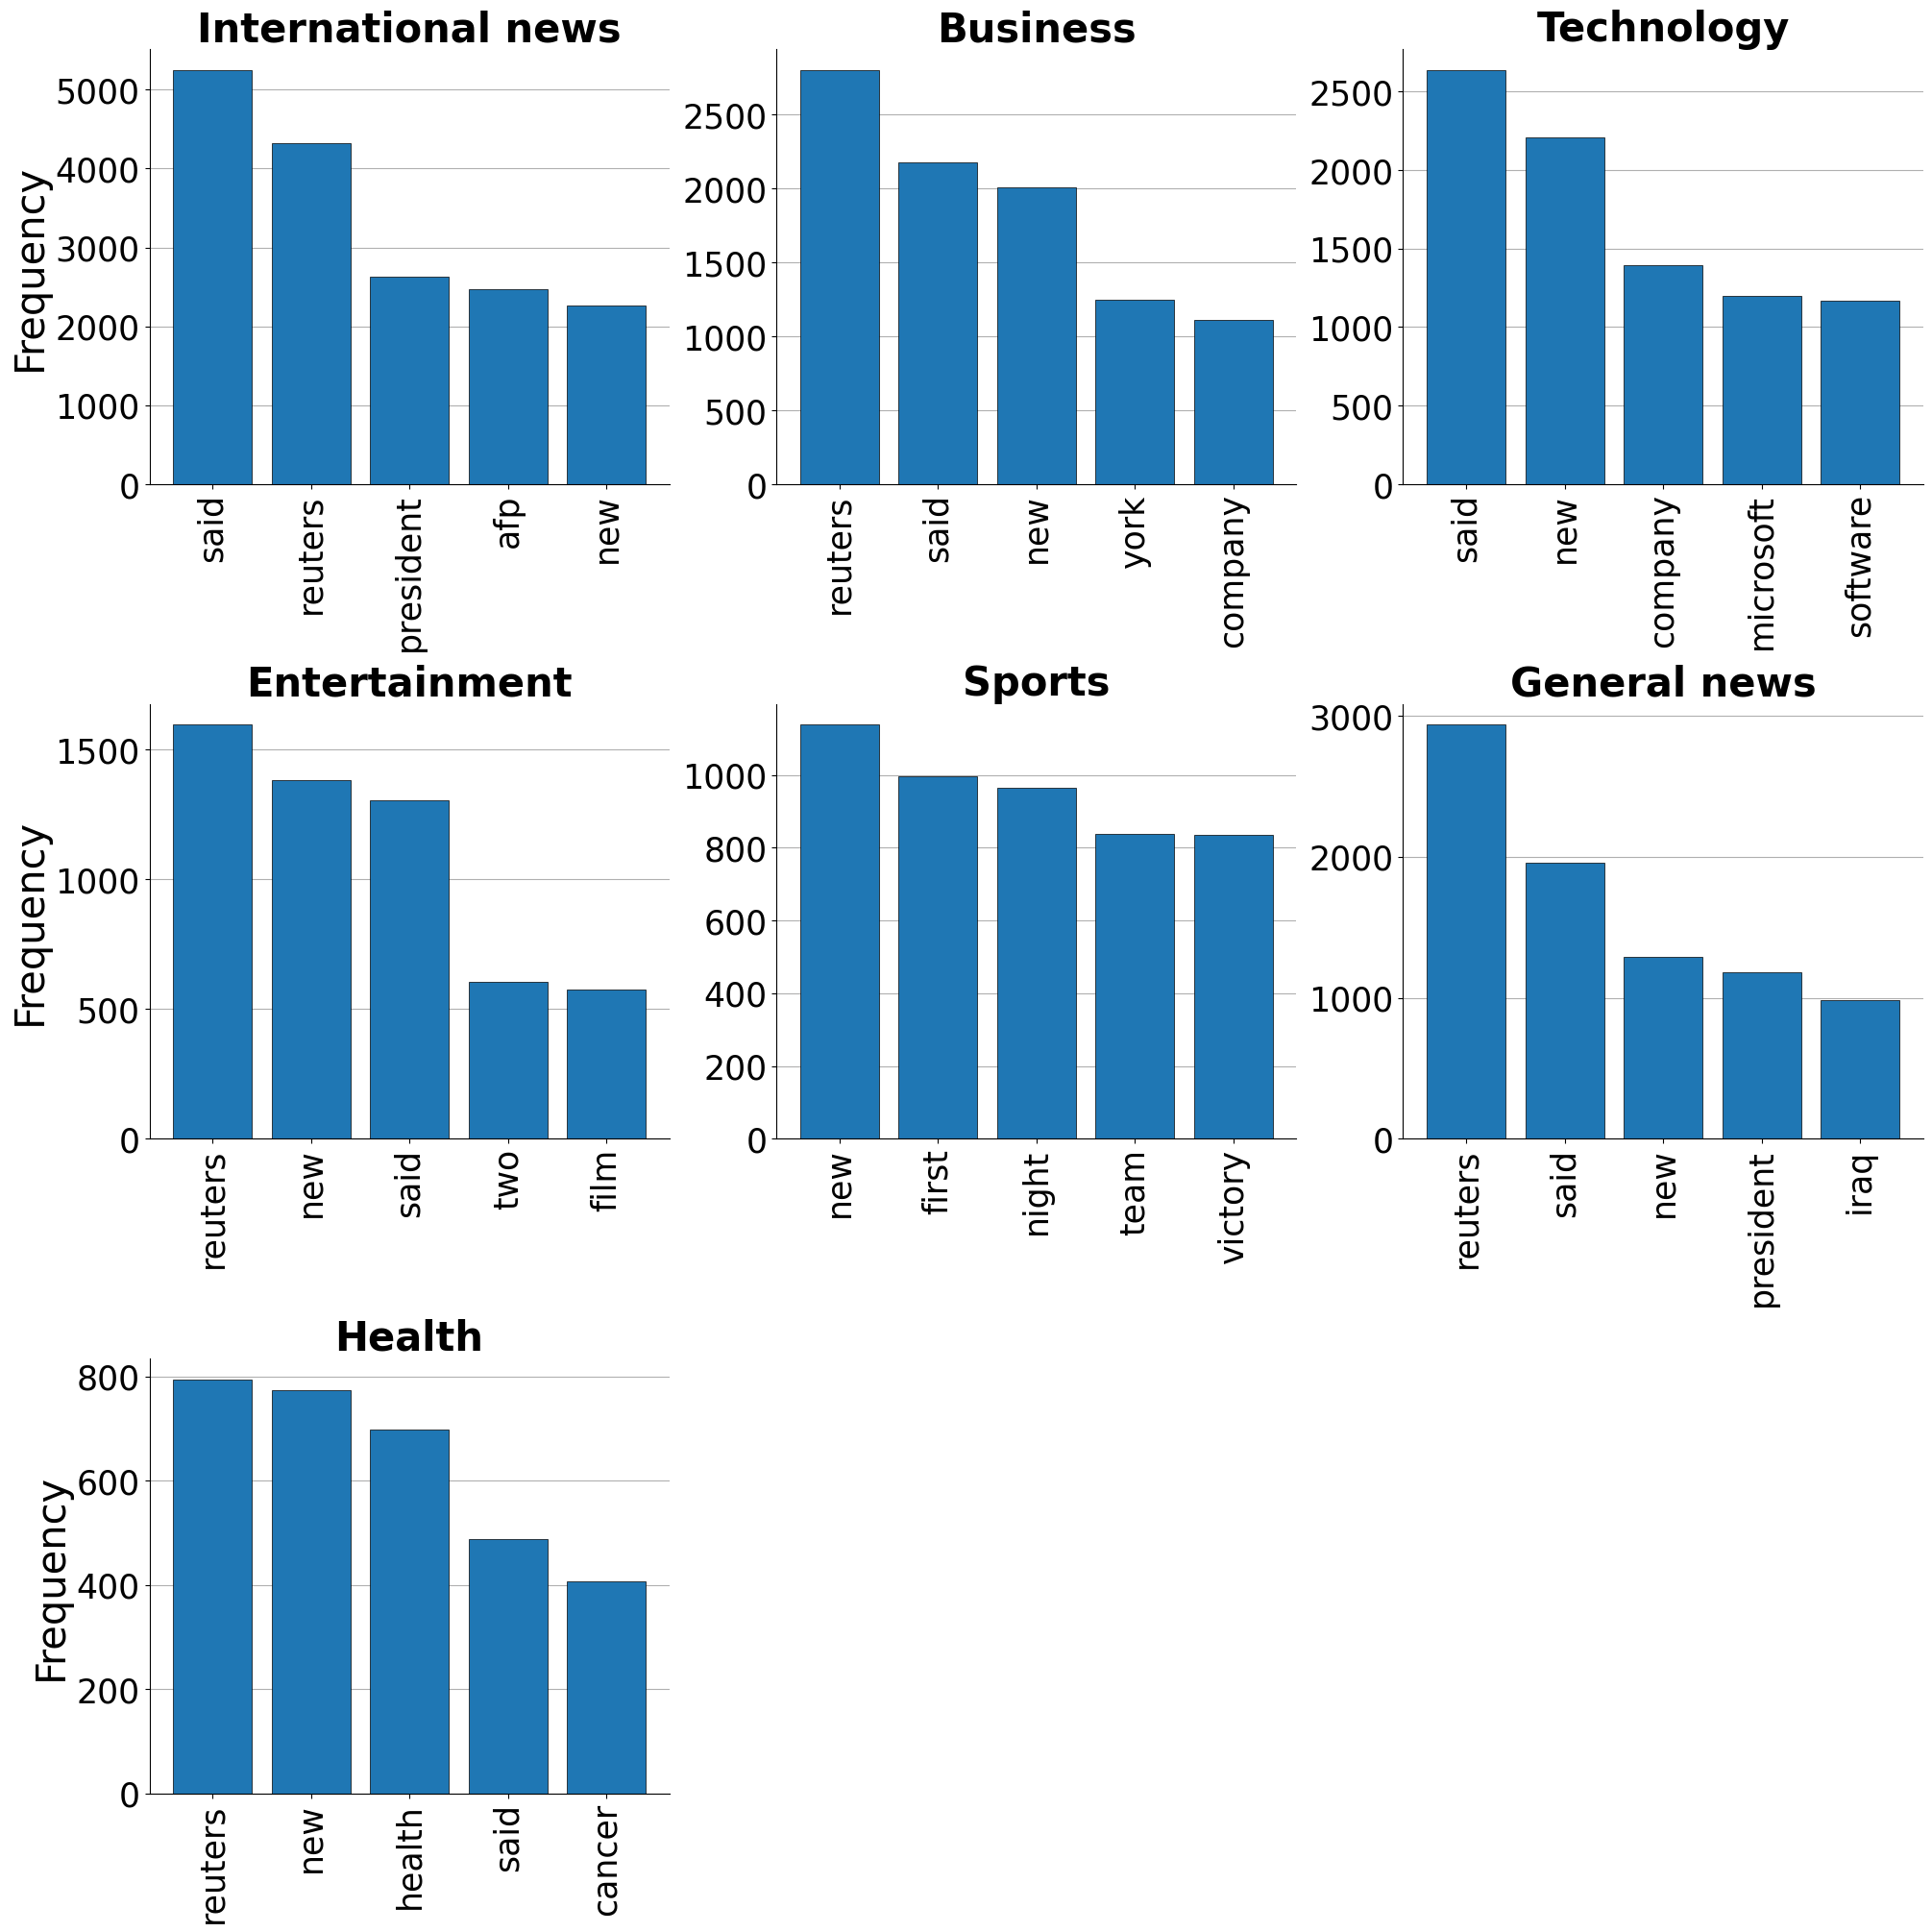

In [14]:
import math
from collections import Counter
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from bs4 import BeautifulSoup 


stop_words = set(stopwords.words('english'))
class_word_counts = {}
target_col = 'article'

for label in range(7):
    articles = df[df['label'] == label][target_col]
    all_words = []
    
    for article in articles:
        soup = BeautifulSoup(str(article), "html.parser")

        if soup.body:
            clean_text = soup.body.get_text(separator=' ')
        else:
            clean_text = soup.get_text(separator=' ')

        clean_text = clean_text.lower()
        words = word_tokenize(clean_text)
        words = [w for w in words if w.isalpha() and w not in stop_words and len(w) > 2]
        all_words.extend(words)
    
    class_word_counts[label] = Counter(all_words).most_common(5)

num_classes = len(class_word_counts)
nrows = 3
ncols = math.ceil(num_classes / nrows)

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(20, 20), constrained_layout=True)

axes_flat = axes.flatten()

for i, (label, words_counts) in enumerate(class_word_counts.items()):
    ax = axes_flat[i]

    if not words_counts:
        continue

    words, counts = zip(*words_counts)

    ax.bar(words, counts, edgecolor='black', linewidth=0.5)

    title_text = label_names.get(label, label)

    ax.set_title(title_text, fontsize=30, fontweight='bold')

    if i % ncols == 0:
        ax.set_ylabel("Frequency", fontsize=30)

    ax.tick_params(axis='x', rotation=90, labelsize=25)
    ax.tick_params(axis='y', labelsize=25)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)

for j in range(i + 1, len(axes_flat)):
    axes_flat[j].axis('off')

plt.show()

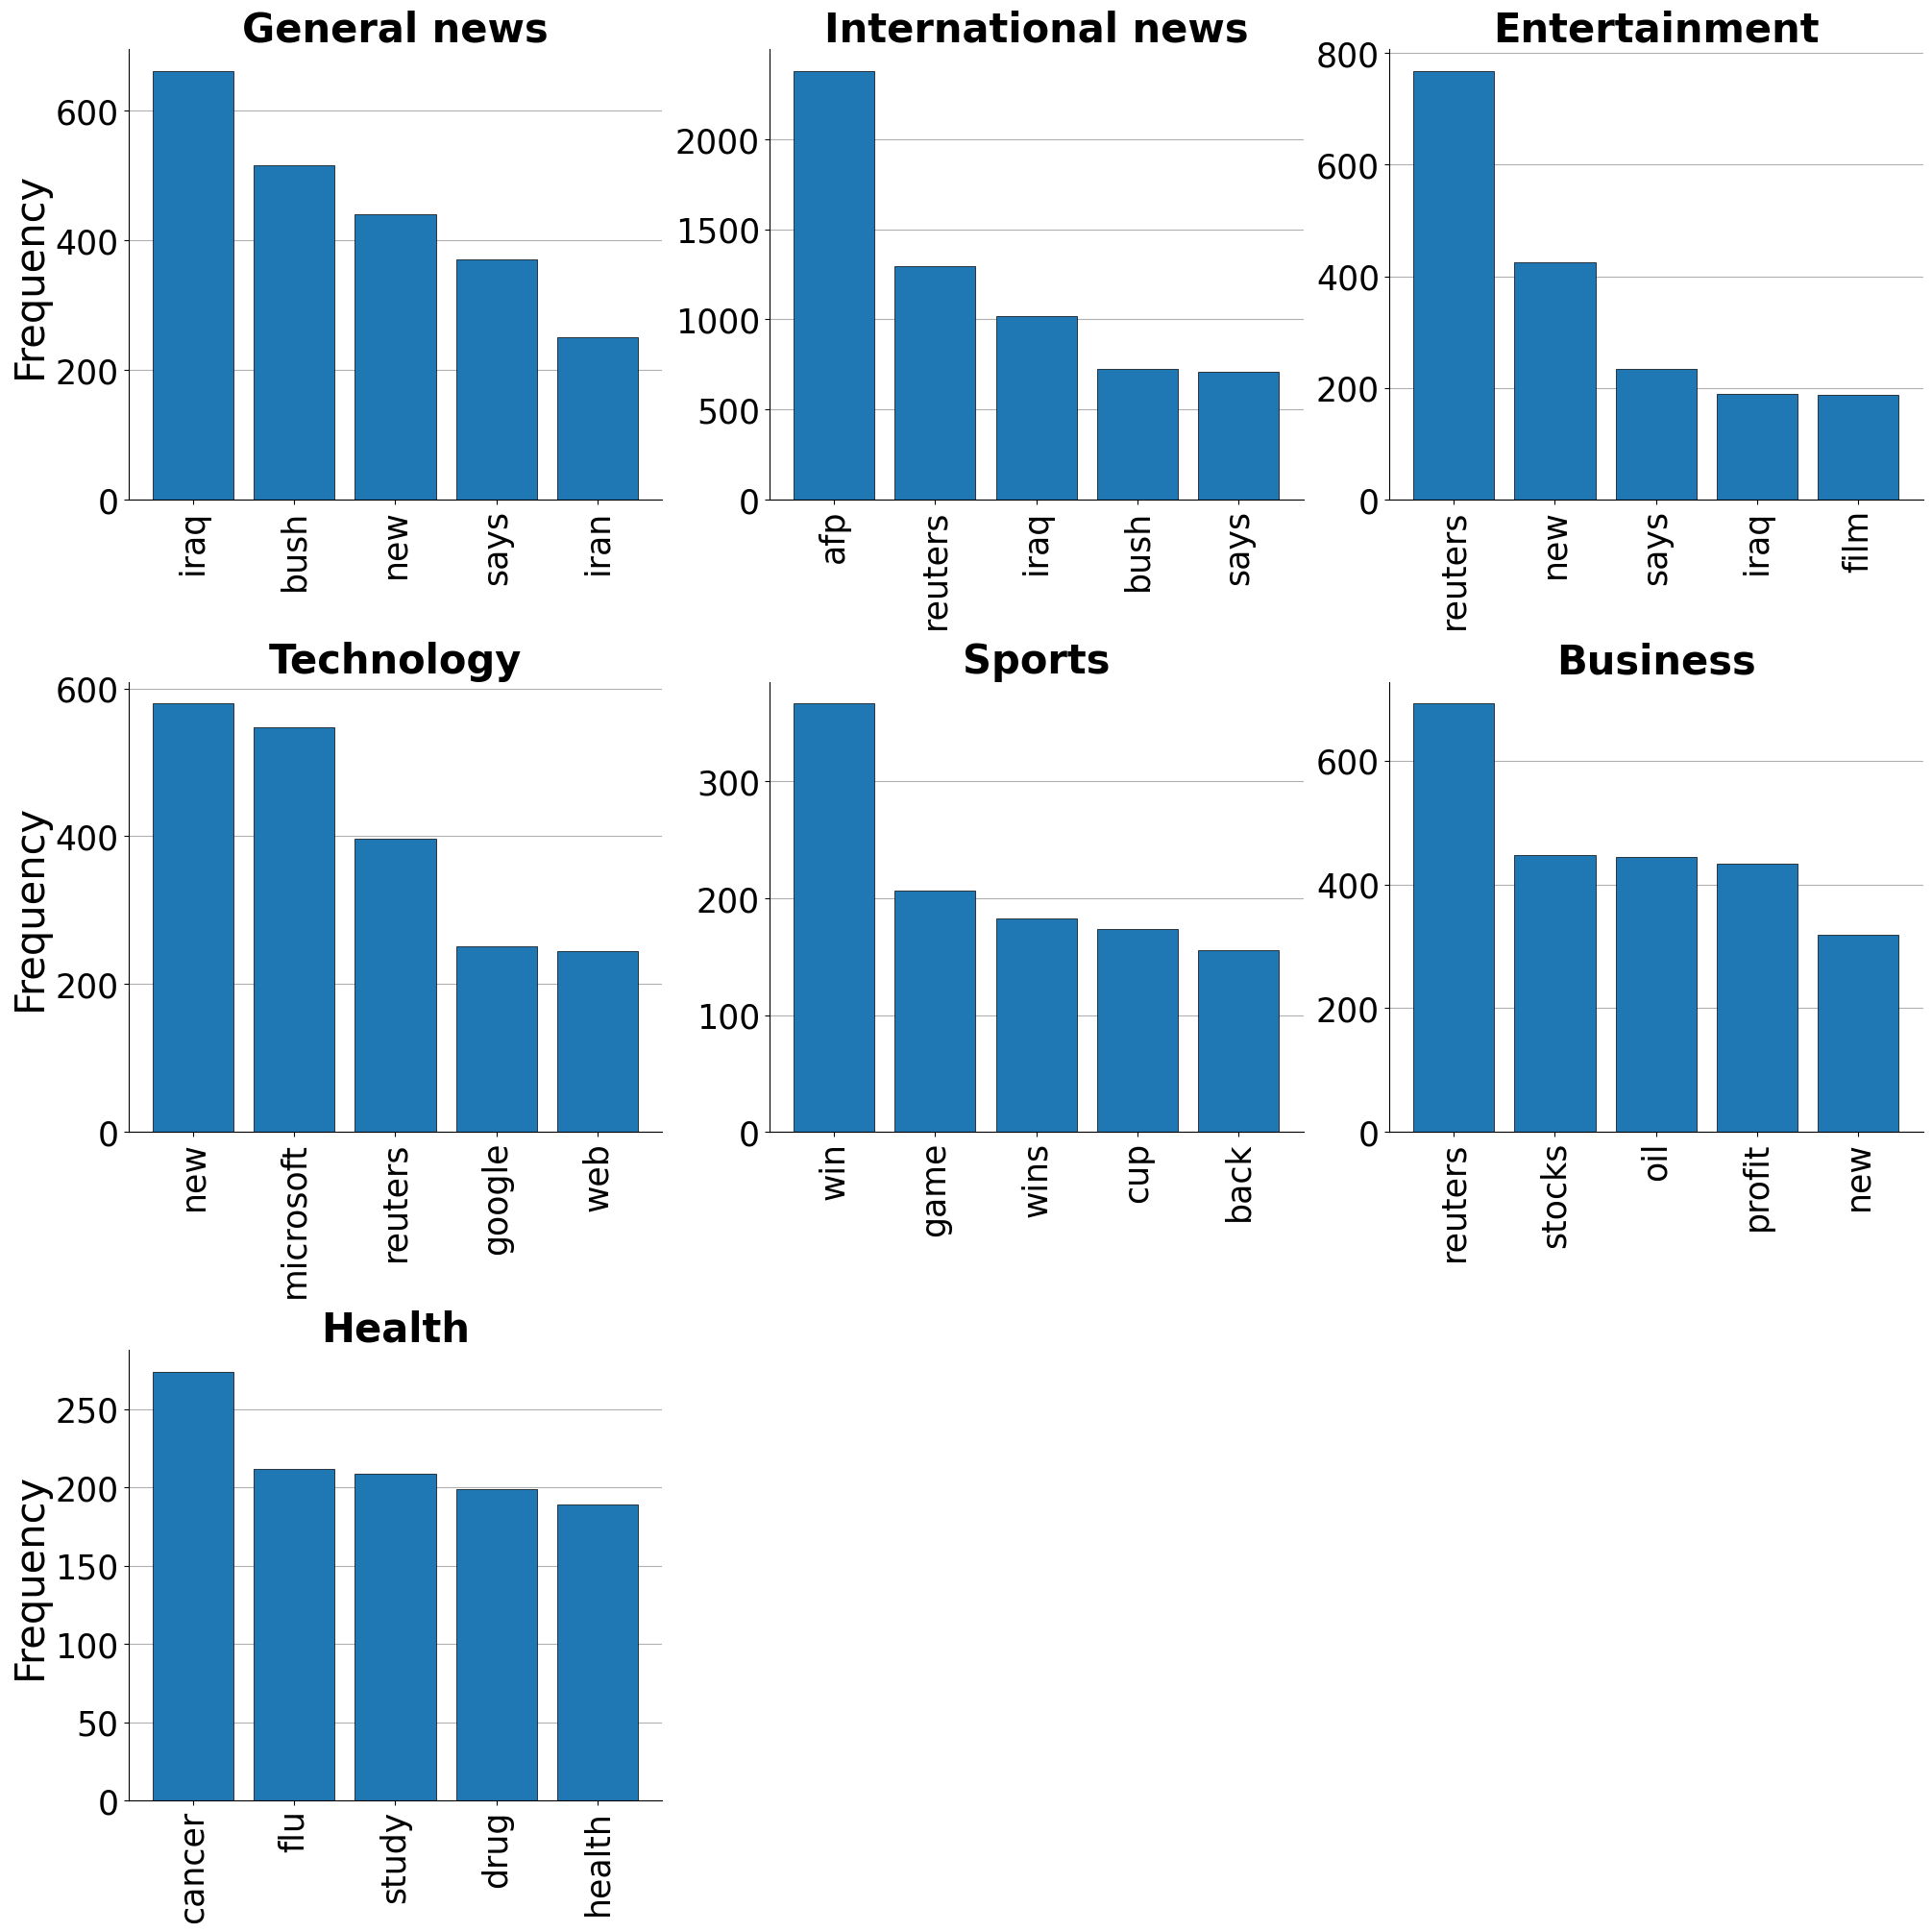

In [15]:
stop_words = set(stopwords.words('english'))
class_word_counts = {}
target_col = 'title'

for label in df['label'].unique():
    articles = df[df['label'] == label][target_col]
    all_words = []
    
    for article in articles:
        article = article.lower()
        words = word_tokenize(article)
        words = [w for w in words if w.isalpha() and w not in stop_words and len(w) > 2]
        all_words.extend(words)
    
    class_word_counts[label] = Counter(all_words).most_common(5)

num_classes = len(class_word_counts)
nrows = 3
ncols = math.ceil(num_classes / nrows)

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(20, 20), constrained_layout=True)

axes_flat = axes.flatten()

for i, (label, words_counts) in enumerate(class_word_counts.items()):
    ax = axes_flat[i]
    
    if not words_counts:
        continue
        
    words, counts = zip(*words_counts)

    ax.bar(words, counts, edgecolor='black', linewidth=0.5)
    
    title_text = label_names.get(label, label)

    ax.set_title(title_text, fontsize=30, fontweight='bold')
    
    if i % ncols == 0:
        ax.set_ylabel("Frequency", fontsize=30)
    
    ax.tick_params(axis='x', rotation=90, labelsize=25)
    ax.tick_params(axis='y', labelsize=25)
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)

for j in range(i + 1, len(axes_flat)):
    axes_flat[j].axis('off')

plt.show()

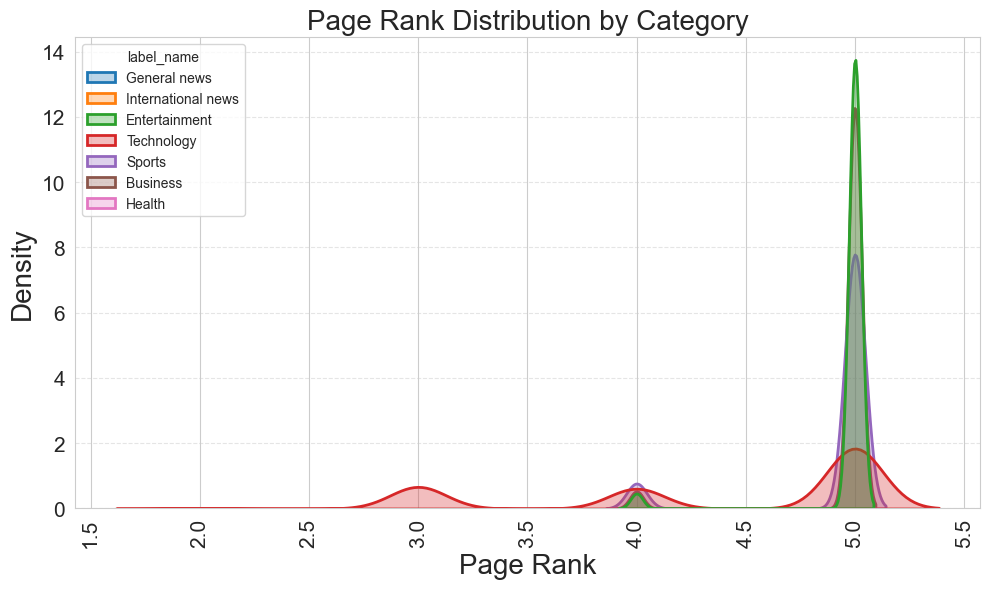

In [100]:
import seaborn as sns

plt.figure(figsize=(10, 6))

df['label_name'] = df['label'].map(lambda x: label_names[x])

sns.kdeplot(
    data=df, 
    x="page_rank", 
    hue="label_name", 
    fill=True, 
    common_norm=False, 
    alpha=0.3, 
    linewidth=2,
    palette="tab10"
)

plt.title("Page Rank Distribution by Category",fontsize=20)
plt.xlabel("Page Rank",fontsize=20)
plt.ylabel("Density",fontsize=20)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tick_params(axis='x', rotation=90, labelsize=15)
plt.tick_params(axis='y',  labelsize=15)
plt.tight_layout()

plt.show()

## Preprocessing

In [135]:
df = df.drop(columns=["timestamp"])

In [102]:
import html

def clean_html(html_content):
    if not isinstance(html_content, str):
        return ""

    soup = BeautifulSoup(html_content, "html.parser")

    for img in soup.find_all("img"):
        src = img.get("src", "")
        alt = img.get("alt", "")
        replacement = f" {alt} {src} ".strip()
        img.replace_with(replacement)

    for a in soup.find_all("a"):
        href = a.get("href", "")
        text = a.get_text(strip=True)
        replacement = f" {text} {href} ".strip()
        a.replace_with(replacement)
    
    text = soup.get_text(separator=" ")

    text = html.unescape(text)

    text = text.replace("\\", " ")

    text = text.replace("_", " ")

    text = re.sub(r'[()\[\]{}]', ' ', text)

    text = re.sub(r'[^\w\s]', ' ', text)

    return text

In [103]:
class LemmaTokenizer(object):
    def __init__(self):
        self.lemmatizer = WordNetLemmatizer()

    def __call__(self, document):
        lemmas = []
        for t in word_tokenize(document):
            lemma = self.lemmatizer.lemmatize(t)   
            lemmas.append(lemma)

        return lemmas

lemmaTokenizer = LemmaTokenizer()

In [ ]:
def compute_top_k_sources(X, y=None,thresh = 0.8):
    sources = set()
    for i in range(7):
        X_i = X[y==i]
        s = X_i["source"].value_counts()
        perc = s.cumsum()/X_i.shape[0]
        s = s[perc<=thresh]
        sources.update(s.keys())
    return sources

def update_sources(X,top_k_sources):
    X["source"] = X["source"].where(X["source"].isin(top_k_sources), other="other")

## Model Selection

# Balancing the dataset

In [136]:
idx_zero = df[df["label"] == 0].index
n_drop = int(0.3*len(idx_zero))
drop_idx = np.random.choice(idx_zero, size=n_drop, replace=False)
df_reduced = df.drop(drop_idx)
X = df_reduced.loc[:,["source","title","article","page_rank"]]
y = df_reduced["label"]

## Parameter tuning of the top k sources

In [106]:
def extract_top_k_sources(df,freq):
    s = df["source"].value_counts()
    perc = s.cumsum()/df.shape[0]
    s = s[perc<=freq]
    return set(s.index)

(72933, 4)


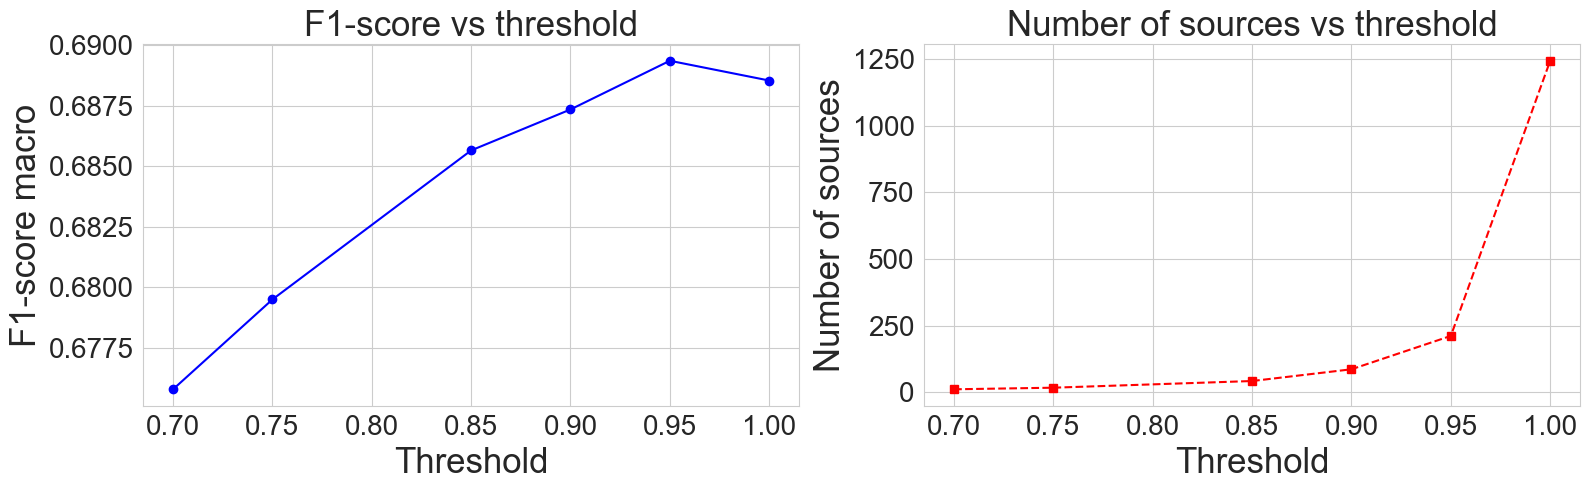

In [107]:
from sklearn.svm import LinearSVC
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score


thresholds = [0.7,0.75,0.85, 0.9,0.95,1]
f1_scores = []
top_k_sizes = []

encoder = OneHotEncoder(handle_unknown='ignore')
scaler = StandardScaler()

preprocessor = ColumnTransformer(transformers = [
    ("title_vectorizer",TfidfVectorizer(),"title"),
    ("article_vectorizer",TfidfVectorizer(),"article"),
    ("encoder",encoder,["source"]),
    ("scaler",scaler,["page_rank"])
])

model = LinearSVC()
pipe = Pipeline(steps=[
    ("preprocessing",preprocessor),
    ("model",model)
])

print(X.shape)
for thresh in thresholds:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    top_k = extract_top_k_sources(X_train, thresh)
    top_k_sizes.append(len(top_k))
    
    update_sources(X_train, top_k)
    pipe.fit(X_train, y_train)

    update_sources(X_test, top_k)
    f1 = f1_score(pipe.predict(X_test), y_test, average="macro")
    f1_scores.append(f1)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))  

ax[0].plot(thresholds, f1_scores, marker='o', linestyle='-', color='b')
ax[0].set_title("F1-score vs threshold",fontsize=25)
ax[0].set_xlabel("Threshold",fontsize=25)
ax[0].set_ylabel("F1-score macro",fontsize=25)
ax[0].tick_params(axis='y', labelsize=20)
ax[0].tick_params(axis='x', labelsize=20)
ax[0].grid(True)

ax[1].plot(thresholds, top_k_sizes, marker='s', linestyle='--', color='r')
ax[1].set_title("Number of sources vs threshold",fontsize=25)
ax[1].set_xlabel("Threshold",fontsize=25)
ax[1].set_ylabel("Number of sources",fontsize=25)
ax[1].tick_params(axis='y', labelsize=20)
ax[1].tick_params(axis='x', labelsize=20)
ax[1].grid(True)

plt.tight_layout()  
plt.show()

## Tuning of the classifier

In [108]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV

preprocessor = ColumnTransformer(
    transformers=[
        ('title_vect', TfidfVectorizer(preprocessor=clean_html,token_pattern=None,  tokenizer=lemmaTokenizer, stop_words="english"), 'title'),
        ('article_vect', TfidfVectorizer(preprocessor=clean_html,token_pattern=None,  tokenizer=lemmaTokenizer, stop_words="english"), 'article'),
        ('source_ohe', OneHotEncoder(handle_unknown='ignore'), ['source']),
        ('scaler', StandardScaler(), ['page_rank'])
    ],
    remainder='drop'
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("clf", LinearSVC())
])


param_grid = {  
    "clf__C": [0.01,0.1,0.3,0.5,0.7,1,1.5,2],
    "clf__class_weight": [None, "balanced"],
    "clf__tol": [1e-4, 1e-8, 1e-12],
    "clf__dual": [True, False]
}


grid = GridSearchCV(
    pipeline,
    param_grid,
    scoring="f1_macro",  
    cv=2,
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print("Best score:", grid.best_score_)
print("Best params:", grid.best_params_)


Fitting 2 folds for each of 96 candidates, totalling 192 fits


Best score: 0.7046277428653381
Best params: {'clf__C': 0.1, 'clf__class_weight': 'balanced', 'clf__dual': True, 'clf__tol': 0.0001}


### Tuning of the Tf-Idf parameters

In [109]:
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score, make_scorer

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
topk = extract_top_k_sources(X_train,0.95)
update_sources(X_train,topk)
update_sources(X_test,topk)

preprocessor = ColumnTransformer(
    transformers=[
        ('title_vect', TfidfVectorizer(preprocessor=clean_html,token_pattern=None,  tokenizer=lemmaTokenizer, stop_words="english"), 'title'),
        ('article_vect', TfidfVectorizer(preprocessor=clean_html,token_pattern=None,  tokenizer=lemmaTokenizer, stop_words="english"), 'article'),
        ('source_ohe', OneHotEncoder(handle_unknown='ignore'), ['source']),
        ('scaler', StandardScaler(), ['page_rank'])
    ],
    remainder='drop'
)

pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearSVC(class_weight='balanced',C=0.1,dual=True,random_state=42))
])

param_distributions = {
    'preprocessor__title_vect__max_df': [0.3,0.4,0.5,0.6,0.7,0.8,0.9],
    'preprocessor__title_vect__min_df': [1,2,3,4,5],
    'preprocessor__title_vect__ngram_range': [(1,1), (1,2), (1,3), (1,4),(1,5)],
    'preprocessor__title_vect__max_features': [25000,50000,75000,100000,150000,300000,None],

    'preprocessor__article_vect__max_df':  [0.3,0.4,0.5,0.6,0.7,0.8,0.9],
    'preprocessor__article_vect__min_df': [1,2,3,4,5],
    'preprocessor__article_vect__ngram_range': [(1,1), (1,2), (1,3), (1,4),(1,5)],
    'preprocessor__article_vect__max_features': [25000,50000,75000,100000,150000,300000,None]
}

f1_scorer = make_scorer(f1_score, average='macro')

random_search = RandomizedSearchCV(
    pipe,
    param_distributions=param_distributions, 
    n_iter=150,       
    scoring=f1_scorer,  
    cv=2,              
    verbose=1,
    n_jobs=-1,
    random_state=42  
)

random_search.fit(X_train, y_train)

print("Best parameters:", random_search.best_params_)
print("Best parameters F1-score (CV):", random_search.best_score_)

y_pred = random_search.predict(X_test)
print("Test F1-score:", f1_score(y_test, y_pred, average='macro'))

Fitting 2 folds for each of 150 candidates, totalling 300 fits
Best parameters: {'preprocessor__title_vect__ngram_range': (1, 3), 'preprocessor__title_vect__min_df': 1, 'preprocessor__title_vect__max_features': 100000, 'preprocessor__title_vect__max_df': 0.3, 'preprocessor__article_vect__ngram_range': (1, 5), 'preprocessor__article_vect__min_df': 1, 'preprocessor__article_vect__max_features': 100000, 'preprocessor__article_vect__max_df': 0.8}
Best parameters F1-score (CV): 0.7165875806374398
Test F1-score: 0.7312557592105853


In [110]:
random_search.best_params_

{'preprocessor__title_vect__ngram_range': (1, 3),
 'preprocessor__title_vect__min_df': 1,
 'preprocessor__title_vect__max_features': 100000,
 'preprocessor__title_vect__max_df': 0.3,
 'preprocessor__article_vect__ngram_range': (1, 5),
 'preprocessor__article_vect__min_df': 1,
 'preprocessor__article_vect__max_features': 100000,
 'preprocessor__article_vect__max_df': 0.8}

In [111]:
preprocessor = ColumnTransformer(
    transformers=[
        ('title_vect', TfidfVectorizer(
            preprocessor=clean_html,
            tokenizer=lemmaTokenizer,
            stop_words="english",
            max_df=0.3,          
            min_df=1,            
            ngram_range=(1, 3),   
            max_features=100000  
        ), 'title'),
        
        ('article_vect', TfidfVectorizer(
            preprocessor=clean_html,
            tokenizer=lemmaTokenizer,
            stop_words="english",
            max_df=0.8,          
            min_df=1,           
            ngram_range=(1, 5), 
            max_features=100000  
        ), 'article'),
        
        ('source_ohe', OneHotEncoder(handle_unknown='ignore'), ['source']),
        ("standardizer", StandardScaler(), ['page_rank'])
    ],
    remainder='drop' 
)

In [137]:

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
top_k = extract_top_k_sources(X_train,0.95)

update_sources(X_train,top_k)

X_train_transformed = preprocessor.fit_transform(X_train)
print(X_train_transformed.shape)
model = LinearSVC(C=0.1,tol=1e-4,random_state=42,class_weight="balanced",dual=True)
model.fit(X_train_transformed, y_train)


(58346, 200217)


LinearSVC(C=0.1, class_weight='balanced', dual=True, random_state=42)

In [138]:
update_sources(X_test,top_k)
X_test_transformed = preprocessor.transform(X_test)
print(f1_score(model.predict(X_test_transformed),y_test,average="macro"))

0.7232753217969002


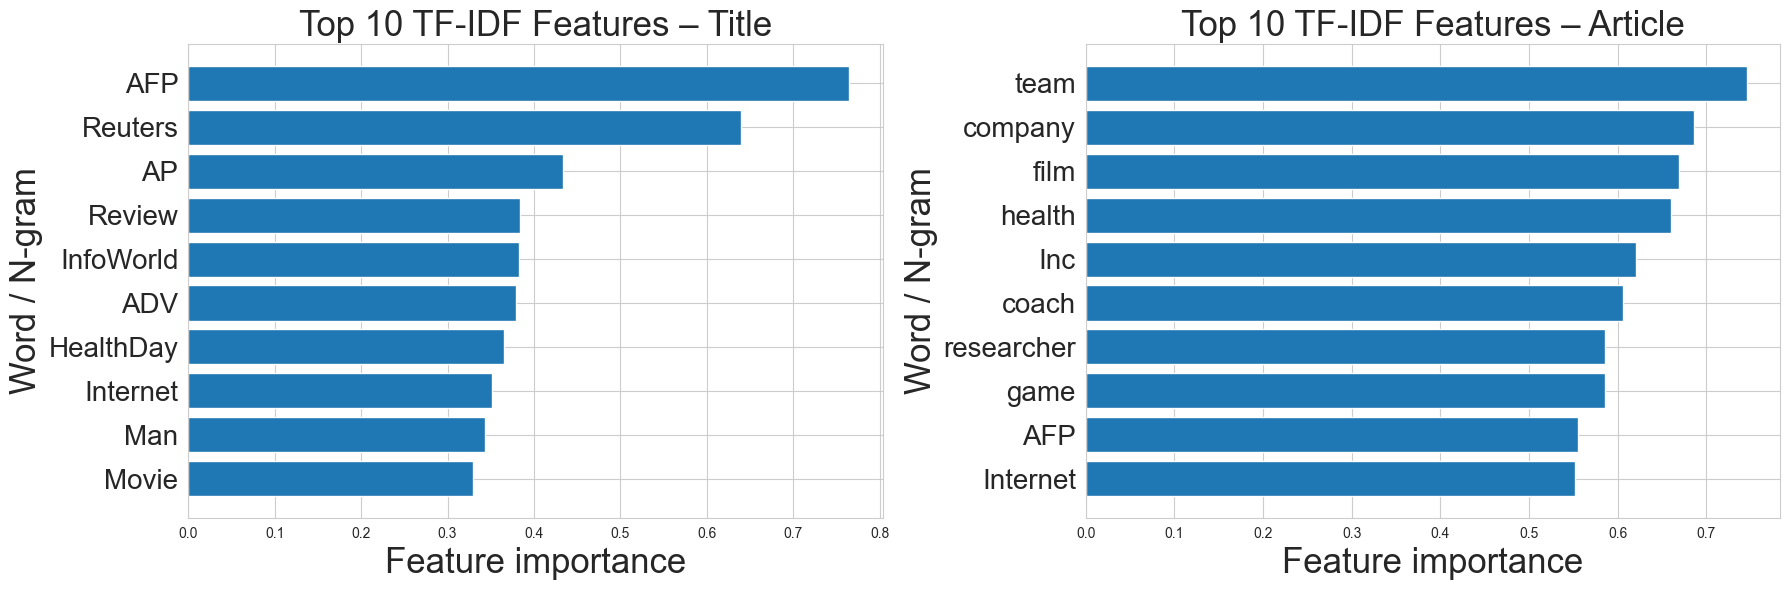

In [139]:

coef = model.coef_


coef = np.mean(np.abs(coef), axis=0)


title_vect = preprocessor.named_transformers_["title_vect"]
article_vect = preprocessor.named_transformers_["article_vect"]

title_features = title_vect.get_feature_names_out()
article_features = article_vect.get_feature_names_out()

n_title = len(title_features)
n_article = len(article_features)


title_coef = coef[:n_title]
article_coef = coef[n_title:n_title + n_article]


def get_top_k(features, weights, k=20):
    idx = np.argsort(weights)[-k:][::-1]
    return features[idx], weights[idx]

top_title_words, top_title_weights = get_top_k(title_features, title_coef, k=10)
top_article_words, top_article_weights = get_top_k(article_features, article_coef, k=10)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].barh(top_title_words[::-1], top_title_weights[::-1])
axes[0].set_title("Top 10 TF-IDF Features – Title",fontsize=25)
axes[0].set_xlabel("Feature importance",fontsize=25)
axes[0].tick_params(axis='y', labelsize=20)
axes[0].set_ylabel("Word / N-gram",fontsize=25)

axes[1].barh(top_article_words[::-1], top_article_weights[::-1])
axes[1].set_title("Top 10 TF-IDF Features – Article",fontsize=25)
axes[1].set_xlabel("Feature importance",fontsize=25)
axes[1].tick_params(axis='y', labelsize=20)
axes[1].set_ylabel("Word / N-gram",fontsize=25)

plt.tight_layout()
plt.show()


In [140]:
update_sources(X_test, top_k)
X_test_transformed = preprocessor.transform(X_test)

y_pred = model.predict(X_test_transformed)

error_analysis = X_test.copy()
error_analysis['True_Label'] = y_test
error_analysis['Predicted_Label'] = y_pred

wrong_predictions = error_analysis[error_analysis['True_Label'] != error_analysis['Predicted_Label']]

print(f"Total errors: {len(wrong_predictions)}")
print("Sample of misclassified rows:")
display(wrong_predictions[0:10])

Total errors: 4043
Sample of misclassified rows:


,source,title,article,page_rank,True_Label,Predicted_Label
79407,BBC,Minimum wage increases to Â£5.35,"The minimum wage rate has increased, but many people in the UK do not get the right amount for their work.",5,5,1
41027,Voice,"700 Dead, 1,000 Missing from Haiti Flooding","Disaster relief operations are underway in Haiti, where about 700 people were killed and at least 1,000 are missing in flooding spawned by Tropical Storm Jeanne.",5,5,3
22827,Reuters,U.S. Warns of Planned Militant Attacks in Kuwait,KUWAIT (Reuters) - The United States has warned Americans in Kuwait that militants are preparing to launch attacks in the U.S.-allied Gulf Arab state and has urged its citizens to be vigilant.,5,5,0
32402,Reuters,Muslim School Set Ablaze as Dutch Mourn Filmmaker,"AMSTERDAM (Reuters) - Arsonists set a Dutch Muslim school ablaze on Tuesday night, the latest in a series of such attacks that came only hours after the cremation of film-maker Theo van Gogh, killed last week by a suspected Islamic militant.",5,3,0
2653,Indian,"MI encouraged us to torture, says US soldier","BERLIN, AUGUST 29: A US soldier expected to plead guilty to charges of abusing Iraqi prisoners told a German magazine he deeply regretted his actions but said the abuses were encouraged by Military Intelligence.",5,0,3
30333,New,Identity Badge Worn Under Skin Approved for Use in Health Care,The F.D.A. cleared the way for a company to market implantable microchips that would provide easy access to medical records.,5,2,6
42062,Christian,Free-market Muslims speed Turkey&#39;s march West as leaders declare <b>...</b>,"As a devout Muslim, Celal Hasnalcaci believes women should cover their hair and dress modestly, as the Koran teaches. As",5,0,5
51137,Reuters,TB case prompts new border safety protocol,"WASHINGTON (Reuters) - New procedures have been put into place at U.S. borders to stop flagged travelers such as the tuberculosis patient who sneaked across the Canadian border last month, U.S. officials said on Wednesday.",5,0,6
79043,Newsday,Medicare costs may drive away almost everyone,We shouldn&#39;t have been so shocked when the Bush administration sneaked out the news under cover of the Labor Day weekend that the Medicare Part B monthly premium is rising next year by 17.,5,6,5
9367,BBC,Sampanis stripped of bronze,Greek weightlifter Leonidas Sampanis is the first Olympic athlete in Athens to lose his medal for a drugs offence.,5,5,4


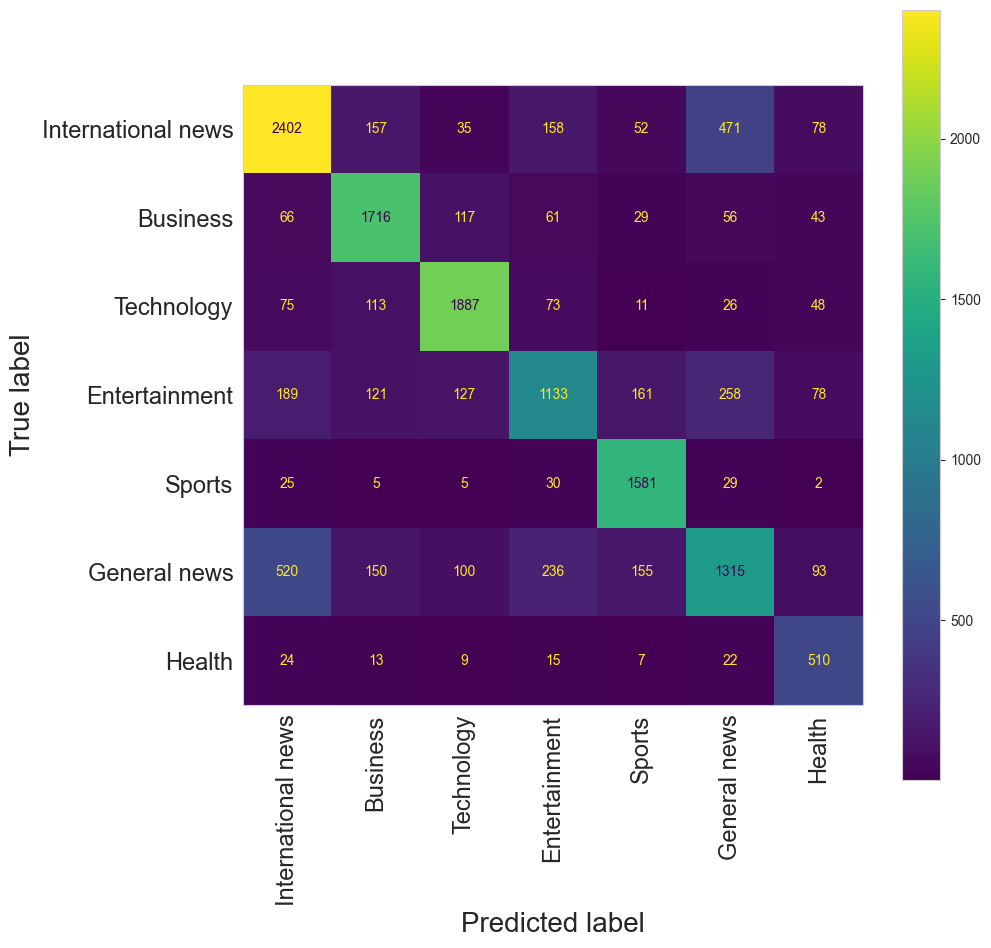

In [143]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true = y_test
y_pred = model.predict(X_test_transformed)

target_names = [label_names[i] for i in sorted(label_names.keys())]

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(10, 10)) 

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)


disp.plot(ax=ax, xticks_rotation='vertical') 
ax.xaxis.label.set_size(20)
ax.yaxis.label.set_size(20)
ax.tick_params(axis='both', which='major', labelsize=17)

plt.grid(False)
plt.show()

In [117]:
y_true = model.predict(X_test_transformed)
wrong_mask = (y_test != y_true)
misclassified = X_test.loc[wrong_mask].copy()  

misclassified["y_true"] = y_test[wrong_mask]
misclassified["y_pred"] = y_true[wrong_mask]

misclassified.loc[:, ["title", "article", "y_true", "y_pred"]].head(20)

,title,article,y_true,y_pred
79418,Poll blow for Hong Kong democrats,Hong Kong's pro-democracy parties are on course to net fewer seats than expected in legislative elections.,5,0
64051,World response muted as smaller country prepares for 3rd incursion,"Smaller but mightier than its neighbors, Rwanda&#39;s greatest clout may come from its nightmare past: a widespread sense around the world that the country was largely abandoned",0,3
27307,E.D.S. President to Become Chief a Little Earlier,"Ronald A. Rittenmeyer will replace Michael H. Jordan as chief executive of Electronic Data Systems on September 1, several months earlier than expected.",2,1
28040,Poor start to High Street sales,"Boxing Day figures reveal poor sales, but bargain hunters are expected to turn out in force for post-Christmas shopping",0,1
9347,Wine shipments face their day in high court,"Terry Speizer wishes he could sell the wines he makes in the cool Edna Valley of California directly to Michigan consumers. In general, alcohol consumed in Michigan must be purchased from",1,3
29778,UK 'has plutonium stockpile',"The UK has built up a stockpile of 100 tonnes of plutonium - enough to make 17,000 nuclear bombs, the Royal Society says.",5,0
51891,Web watch: Google desktop,"Google&#39;s Desktop Search application, released as a preview this month for Windows XP and 2000 PCs, searches the hard drive of your PC using the same algorithms that have made its Internet search engine fast, accurate and popular.",3,2
61179,Dick Clark Still Hospitalized,"TV personality-producer Dick Clark will spend Christmas, and perhaps New Year&#39;s Eve, in a hospital where he&#39;s recovering from a mild stroke, his spokesman said Tuesday.",5,3
25116,Update 4: Blockbuster to Make Hollywood Hostile Bid,Blockbuster Inc. said Tuesday it will launch a hostile bid for Hollywood Entertainment Corp. next month if the rival&#39;s directors won&#39;t negotiate a deal.,3,1
20593,Roman empires to collide,Chelsea&#39;s 3-1 win against FC Porto was not owner Roman Abramovich&#39;s only reason to smile after Champions League action on Wednesday.,5,4


In [119]:
df = pd.read_csv("evaluation.csv")
X = df.loc[:,["source","title","article","page_rank"]]

X["title"] = X["title"].fillna("")
X["article"] = X["article"].fillna("")

update_sources(X,top_k)
X_transformed = preprocessor.transform(X)
y=model.predict(X_transformed)

In [ ]:
submission = pd.DataFrame({
    'Id': range(len(y)), 
    'Predicted': y
})

submission.to_csv("submission.csv", index=False)

print("File 'submission.csv' created succesfully!")

File 'submission.csv' created succesfully!
